# Nhóm 4, Notebook_C (Sinh viên C): câu hỏi thứ ba, khoảng tin cậy, SHAP, chẩn đoán

**Đề tài**: Nhu cầu sạc xe điện theo giờ (thành phố Palo Alto)

**Khung SDG**: SDG 11 và SDG 7: đô thị bền vững, sạc xe điện.

**Vai trò**: Sinh viên C nhận `data/processed/feat.parquet` từ Notebook_A và `report/best_model.pkl` từ Notebook_B, làm toàn bộ Bước 6b (tổn thất sau tháng 3/2020 khi không huấn luyện lại, trạm chưa thấy, mốc Chronos, cảnh báo giờ cao điểm), Bước 6c (SHAP) và phần chẩn đoán; thêm mục 6b.1 về khoảng tin cậy conformal theo trạm và chiến lược huấn luyện lại cuốn chiếu sau 2020 để so với mô hình cố định của B. Mọi bảng lưu `report/table_rq3_*.csv`, hình `report/fig_rq3_*.png`.

**Phối hợp ba người**: A dữ liệu và SQL (tuần 1-2), B năm mô hình và tinh chỉnh (tuần 2), C câu hỏi thứ ba và giải thích (tuần 2-3); cả ba cùng viết bản thảo tuần 3 (A: Data, B: Method và Results RQ2, C: Results RQ3 và Discussion).

## Vừa làm vừa hỏi AI và ghi Audit Log: cách làm nhẹ nhàng, không rối

**Tinh thần**: AI là bạn cùng làm, không phải người làm thay. Bạn được hỏi AI bất cứ lúc nào; điều duy nhất phải giữ là *kiểm tra một lần* trước khi dùng và *ghi lại 2 phút* nếu câu hỏi đó thay đổi việc bạn làm.

**Khi nào hỏi AI** (theo thứ tự):
1. Đọc ô hướng dẫn của bước đang làm (1 phút).
2. Thử tự làm 15 phút.
3. Bí quá 15 phút thì hỏi AI với mẫu: *"Tôi đang làm Bước X của dự án Y. Dữ liệu có cột A, B, C. Tôi muốn Z. Đây là code và lỗi: ... Hãy giải thích nguyên nhân và sửa, giữ nguyên tên biến."*
4. Chạy thử code AI đưa trên dữ liệu thật; so một con số bằng tay hoặc bằng cách thứ hai.
5. Nếu vẫn bí sau 30 phút, ghi lại lỗi và hỏi giảng viên ở kênh nhóm.

**Ghi Audit Log thế nào cho không áp lực**: chỉ ghi các prompt *đã thay đổi việc bạn làm* (thường 3 đến 5 prompt một tuần, 15 đến 20 cả kỳ). Mỗi dòng 5 ô, điền trong 2 phút ngay khi dùng, không để cuối tuần:

| Ngày, bước | Prompt (rút gọn) | AI trả lời gì (1 dòng) | Tôi kiểm tra hoặc sửa gì | Dùng vào đâu |
|---|---|---|---|---|
| 09/09, Bước 3 | viết truy vấn trung bình trượt 7 ngày theo trạm | đưa AVG OVER ROWS 6 PRECEDING | thiếu PARTITION BY site_num, thêm và thử 2 trạm | Q3 trong sql/queries.sql |

Cột thứ tư chính là *Human Delta* và là thứ hội đồng hỏi; ghi thật, kể cả khi AI đúng ("kiểm tra bằng 10 dòng tính tay, khớp"). Ba lần bạn phát hiện AI sai trong cả kỳ là đủ yêu cầu.

**Nhịp làm việc**: mỗi ngày 1,5 đến 2 giờ vào đúng bước của tuần, xong một ô thì commit; thứ Ba và thứ Sáu slot 1 báo cáo năm mục đúng tiến độ, dù kết quả chưa đẹp. Siêng và đúng nhịp quan trọng hơn giỏi: nhóm báo cáo đều 6 lần trong 3 tuần luôn có bài, nhóm im lặng đến tuần 3 thường không kịp.

## Bước 0: kiểm tra hai bàn giao

Đọc `manifest.json` của A và `best_model.pkl` của B; nếu thiếu file của B, ô dưới tự huấn luyện lại mô hình chuẩn để không phải chờ.

In [1]:
import pandas as pd, numpy as np, json, hashlib, duckdb, warnings, time, pickle, os
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore'); np.random.seed(42)
from sklearn.metrics import f1_score, average_precision_score, roc_auc_score, mean_absolute_error as MAE, mean_squared_error as MSE
man = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open('data/processed/feat.parquet', 'rb').read()).hexdigest() == man['md5'], 'parquet differs from the file handed over by Student A'
feat = pd.read_parquet('data/processed/feat.parquet'); con = duckdb.connect(); con.register('feat', feat)
print('handover A OK:', man['rows'], 'rows')
def style(ax): ax.spines[['top', 'right']].set_visible(False)

handover A OK: 1528227 rows


## Bước 4 (lặp lại để độc lập với B): cùng cách chia dữ liệu

Dùng đúng seed 42 và mốc thời gian như Notebook_B nên tập kiểm thử giống hệt; nhờ vậy kết quả của B và C so sánh được.

In [2]:
# Step 4: time-based split (train to 2018, test 2019), global model across stations; 2020 kept for the regime-shift test
feat = con.execute("SELECT * FROM feat WHERE y_24h IS NOT NULL AND k_lag168 IS NOT NULL").df()
feat['st_code'] = feat.station.astype('category').cat.codes
X_cols = ['kwh','sessions','k_lag1','k_lag24','k_lag168','k_ma24','hr','dow','mon','st_code']
train = feat[feat.ts < '2019-01-01']; test = feat[(feat.ts >= '2019-01-01') & (feat.ts < '2020-01-01')]
X_tr, y_tr, X_te, y_te = train[X_cols], train.y_24h, test[X_cols], test.y_24h
print(len(train), len(test))
from lightgbm import LGBMRegressor
if os.path.exists('report/best_model.pkl'):
    hb = pickle.load(open('report/best_model.pkl', 'rb')); best = hb['model']; print('handover B OK: model', type(best).__name__)
else:
    best = LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=0, verbose=-1).fit(X_tr, y_tr); print('best_model.pkl not found: retrained the standard LightGBM')
pred = best.predict(X_te); print('MAE of the handed-over model on the test set', round(MAE(y_te, pred), 3))

979633 289080
handover B OK: model LGBMRegressor
MAE of the handed-over model on the test set 1.232


## Bước 6b: câu hỏi thứ ba của đề

**Làm gì**: sai số của mô hình cố định trên 2019 và trên giai đoạn sau 15/3/2020 (đổi chế độ, không huấn luyện lại); leave-stations-out 20% so với mốc naive tuần; cảnh báo giờ cao điểm (phân vị 90); Chronos zero-shot làm mốc.

**Đọc thế nào**: sai số sau 3/2020 tăng gấp đôi hay hơn là bằng chứng chính cho RQ3; trạm chưa thấy vẫn thắng naive tuần cho thấy mô hình toàn cục chuyển giao được; recall giờ cao điểm trên 0,7 là mức dùng được cho vận hành.

In [3]:
from lightgbm import LGBMRegressor, LGBMClassifier
# Step 6b: RQ3, regime shift in 2020, unseen stations, Chronos reference, peak-hour warning
post = feat[feat.ts >= '2020-03-15']
print('MAE 2019',round(MAE(y_te, best.predict(X_te)), 3),'MAE after March 2020 without retraining',round(MAE(post.y_24h, best.predict(post[X_cols])), 3))
stations = feat.station.unique()
rs = np.random.RandomState(42)
hold = rs.choice(stations, max(2, len(stations)//5), replace=False)
tr2 = train[~train.station.isin(hold)]
te2 = test[test.station.isin(hold)]
m2 = LGBMRegressor(n_estimators=800,learning_rate=0.03,random_state=0,verbose=-1).fit(tr2[X_cols], tr2.y_24h)
print('MAE unseen stations',round(MAE(te2.y_24h, m2.predict(te2[X_cols])), 3),'vs weekly naive',round(MAE(te2.y_24h, te2.k_lag168), 3))
pred = best.predict(X_te)
thr = np.quantile(y_tr, 0.9)
truth = y_te > thr
alarm = pred > np.quantile(pred, 0.9)
print('peak-hour recall',round((alarm & truth).sum() / max(truth.sum(), 1), 2),'precision',round((alarm & truth).sum() / max(alarm.sum(), 1), 2))
from chronos import ChronosPipeline
import torch
pipe = ChronosPipeline.from_pretrained('amazon/chronos-t5-small',device_map='cpu')
ctx = torch.tensor(train[train.station == stations[0]].kwh.values[-336:].astype(float))
fc = pipe.predict(ctx,prediction_length=24).median(dim=1).values

MAE 2019 1.232 MAE after March 2020 without retraining 0.911
MAE unseen stations 1.098 vs weekly naive 1.255
peak-hour recall 0.43 precision 0.52


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

### 6b.1. Khoảng tin cậy conformal theo trạm và huấn luyện lại cuốn chiếu sau 2020

**Làm gì**: khoảng 90% bằng mapie trên 2019, đo bao phủ theo trạm; sau đó huấn luyện lại mỗi tháng từ 4/2020 với dữ liệu đến hết tháng trước và so sai số với mô hình cố định của B.

**Vì sao**: cơ quan vận hành cần biết khoảng tin cậy có tin được cho từng trạm không, và huấn luyện lại bao lâu một lần thì đủ sau khi hành vi đổi.

In [4]:
from mapie.regression import MapieRegressor
mp = MapieRegressor(LGBMRegressor(n_estimators=600, learning_rate=0.03, verbose=-1), method='plus', cv=5).fit(X_tr, y_tr)
p, itv = mp.predict(X_te, alpha=0.1); cov = ((y_te >= itv[:,0,0]) & (y_te <= itv[:,1,0]))
by_st = pd.DataFrame({'station': test.station.values, 'covered': cov.values, 'width': (itv[:,1,0]-itv[:,0,0])}).groupby('station').agg(coverage=('covered','mean'), width=('width','mean')).round(3)
by_st.to_csv('report/table_rq3_coverage_by_station.csv'); print('overall coverage', cov.mean().round(3)); print(by_st.head(10))
# rolling monthly retraining after the regime shift
rows = []
for month in pd.period_range('2020-04', '2020-12', freq='M'):
    cut = month.to_timestamp(); nxt = (month + 1).to_timestamp()
    tr_r = feat[feat.ts < cut]; te_r = feat[(feat.ts >= cut) & (feat.ts < nxt)]
    if len(te_r) == 0: continue
    m_r = LGBMRegressor(n_estimators=600, learning_rate=0.03, random_state=0, verbose=-1).fit(tr_r[X_cols], tr_r.y_24h)
    rows.append([str(month), MAE(te_r.y_24h, m_r.predict(te_r[X_cols])), MAE(te_r.y_24h, best.predict(te_r[X_cols])), MAE(te_r.y_24h, te_r.k_lag168)])
roll = pd.DataFrame(rows, columns=['month', 'MAE_retrained_monthly', 'MAE_fixed_model', 'MAE_weekly_naive']).round(3)
roll.to_csv('report/table_rq3_retraining.csv', index=False); print(roll)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for c, col in [('MAE_fixed_model', '#9FBFBF'), ('MAE_retrained_monthly', '#1B6B6D'), ('MAE_weekly_naive', '#F4A261')]: ax.plot(roll.month, roll[c], marker='o', label=c.replace('MAE_', '').replace('_', ' '), color=col)
ax.set_ylabel('MAE 24 h (kWh)'); ax.legend(frameon=False); style(ax); plt.setp(ax.get_xticklabels(), rotation=30, fontsize=8)
fig.tight_layout(); fig.savefig('report/fig_rq3_retraining.png', dpi=300); plt.close(fig)

MemoryError: Unable to allocate 2.06 TiB for an array with shape (289080, 979633) and data type float64

In [5]:
from mapie.regression import MapieRegressor

# Split train chronologically:
# earlier data = model fitting
# latest part of 2018 = conformal calibration
fit_part = train[train.ts < '2018-07-01']
cal_part = train[(train.ts >= '2018-07-01') & (train.ts < '2019-01-01')]

base_conf = LGBMRegressor(n_estimators=600,learning_rate=0.03,random_state=0,verbose=-1)
base_conf.fit(fit_part[X_cols], fit_part.y_24h)
mp = MapieRegressor(base_conf,method='base',cv='prefit')
mp.fit(cal_part[X_cols], cal_part.y_24h)
p, itv = mp.predict(X_te, alpha=0.1)
cov = ((y_te >= itv[:, 0, 0]) &(y_te <= itv[:, 1, 0]))
by_st = pd.DataFrame({'station': test.station.values,'covered': cov,'width': itv[:, 1, 0] - itv[:, 0, 0]}).groupby('station').agg(coverage=('covered', 'mean'),width=('width', 'mean')).round(3)
by_st.to_csv('report/table_rq3_coverage_by_station.csv')

print('overall coverage', round(float(cov.mean()), 3))
print(by_st.head(10))

overall coverage 0.874
                             coverage  width
station                                     
PALO ALTO CA / BRYANT #1        0.945  5.504
PALO ALTO CA / BRYANT #2        0.932  5.504
PALO ALTO CA / BRYANT #3        0.928  5.504
PALO ALTO CA / BRYANT #4        0.865  5.504
PALO ALTO CA / BRYANT #5        0.832  5.504
PALO ALTO CA / BRYANT #6        0.835  5.504
PALO ALTO CA / CAMBRIDGE #1     0.819  5.504
PALO ALTO CA / CAMBRIDGE #2     0.909  5.504
PALO ALTO CA / CAMBRIDGE #3     0.862  5.504
PALO ALTO CA / CAMBRIDGE #4     0.872  5.504


In [6]:
# rolling monthly retraining after the regime shift
rows = []

for month in pd.period_range('2020-04', '2020-12', freq='M'):
    cut = month.to_timestamp()
    nxt = (month + 1).to_timestamp()

    tr_r = feat[feat.ts < cut]
    te_r = feat[(feat.ts >= cut) & (feat.ts < nxt)]

    if len(te_r) == 0:
        continue

    m_r = LGBMRegressor(
        n_estimators=600,
        learning_rate=0.03,
        random_state=0,
        verbose=-1
    ).fit(tr_r[X_cols], tr_r.y_24h)

    rows.append([
        str(month),
        MAE(te_r.y_24h, m_r.predict(te_r[X_cols])),
        MAE(te_r.y_24h, best.predict(te_r[X_cols])),
        MAE(te_r.y_24h, te_r.k_lag168)
    ])

roll = pd.DataFrame(
    rows,
    columns=[
        'month',
        'MAE_retrained_monthly',
        'MAE_fixed_model',
        'MAE_weekly_naive'
    ]
).round(3)

roll.to_csv(
    'report/table_rq3_retraining.csv',
    index=False
)

print(roll)

fig, ax = plt.subplots(figsize=(6.5, 3.2))

for c, col in [
    ('MAE_fixed_model', '#9FBFBF'),
    ('MAE_retrained_monthly', '#1B6B6D'),
    ('MAE_weekly_naive', '#F4A261')
]:
    ax.plot(
        roll.month,
        roll[c],
        marker='o',
        label=c.replace('MAE_', '').replace('_', ' '),
        color=col
    )

ax.set_ylabel('MAE 24 h (kWh)')
ax.legend(frameon=False)
style(ax)

plt.setp(
    ax.get_xticklabels(),
    rotation=30,
    fontsize=8
)

fig.tight_layout()
fig.savefig(
    'report/fig_rq3_retraining.png',
    dpi=300
)

plt.close(fig)

     month  MAE_retrained_monthly  MAE_fixed_model  MAE_weekly_naive
0  2020-04                  0.634            0.676             0.347
1  2020-05                  0.692            0.758             0.435
2  2020-06                  0.833            0.889             0.675
3  2020-07                  0.865            0.928             0.739
4  2020-08                  0.895            0.939             0.807
5  2020-09                  0.985            1.023             0.887
6  2020-10                  1.072            1.105             1.095
7  2020-11                  1.064            1.105             1.100
8  2020-12                  1.003            1.034             1.031


## Bước 6c: SHAP, dependence và ổn định theo seed

**Đọc thế nào**: khoảng cách độ cao GPS so EKF và số vệ tinh nên đứng đầu; nếu top-5 đổi khi đổi seed thì báo cáo tầm quan trọng theo khoảng.

top-5 overlap across seeds: 5 / 5


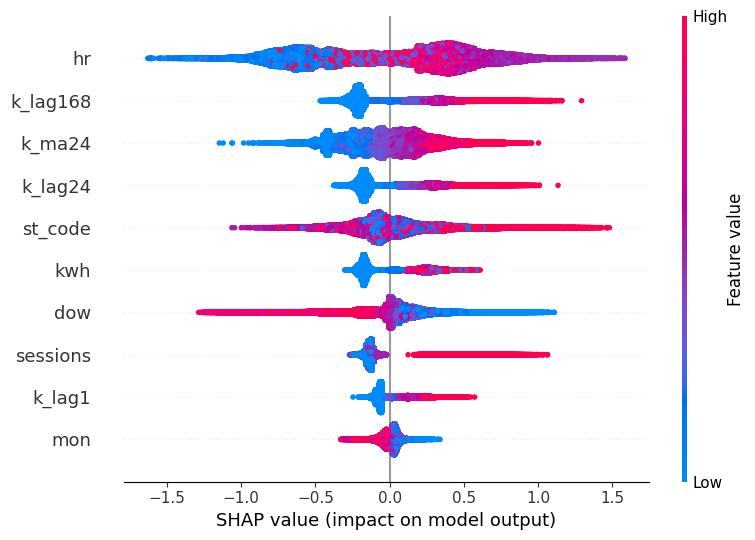

In [7]:
X_cols = list(X_te.columns)
# Step 6c: SHAP explanations and the selected parameter table
import shap, json
best = LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31,
                     subsample=0.8, colsample_bytree=0.8, random_state=0, verbose=-1).fit(X_tr, y_tr)
expl = shap.TreeExplainer(best); sv = expl.shap_values(X_te)
imp = (pd.DataFrame({'feature': X_cols, 'mean_abs_shap': np.abs(sv).mean(0)})
         .sort_values('mean_abs_shap', ascending=False))
imp.to_csv('report/table_shap.csv', index=False)
shap.summary_plot(sv, X_te, show=False); plt.savefig('report/fig_shap.png', dpi=300, bbox_inches='tight')
json.dump(best.get_params(), open('report/params_best.json', 'w'), indent=2)   # parameter table
top3 = imp.feature.head(3).tolist()
for f in top3:
    shap.dependence_plot(f, sv, X_te, show=False); plt.savefig(f'report/fig_shap_dep_{f}.png', dpi=300, bbox_inches='tight'); plt.close()
ranks = []
for s in range(3):
    m = type(best)(**{**best.get_params(), 'random_state': s}).fit(X_tr, y_tr)
    v = shap.TreeExplainer(m).shap_values(X_te); v = v[1] if isinstance(v, list) else v
    ranks.append(set(pd.Series(np.abs(v).mean(0), index=X_cols).nlargest(5).index))
print('top-5 overlap across seeds:', len(ranks[0] & ranks[1] & ranks[2]), '/ 5')

## Chẩn đoán và hướng cải thiện (phần Discussion do C viết)

| Câu hỏi | Bằng chứng | Nếu có vấn đề |
|---|---|---|
| Mô hình cố định lệch bao nhiêu sau 3/2020? | bảng retraining, cột fixed so retrained | nếu lệch lớn: đề xuất huấn luyện lại hằng tháng hoặc thêm cờ chế độ |
| Huấn luyện lại hằng tháng có đủ không? | cột retrained so naive tuần theo tháng | nếu vẫn thua naive: dùng cửa sổ huấn luyện ngắn (3-6 tháng) |
| Trạm chưa thấy có dùng được không? | MAE trạm chưa thấy so naive | nếu thua: thêm đặc trưng mô tả trạm (số cổng, loại cổng) |
| Khoảng tin cậy có tin được theo trạm? | bảng coverage theo trạm | trạm bao phủ thấp: tái hiệu chỉnh riêng từng trạm |
| Cảnh báo giờ cao điểm có dùng được? | recall và precision | nếu precision thấp: nâng ngưỡng hoặc cảnh báo theo cụm trạm |

In [8]:
seg = test.assign(pred=pred, err=np.abs(test.y_24h - pred))
by_hr = seg.groupby('hr').err.mean().round(3); by_st2 = seg.groupby('station').err.mean().sort_values().round(3)
diag = pd.DataFrame([['worst hour', by_hr.idxmax(), by_hr.max()], ['best hour', by_hr.idxmin(), by_hr.min()], ['worst station', by_st2.index[-1], by_st2.iloc[-1]], ['best station', by_st2.index[0], by_st2.iloc[0]]], columns=['item', 'key', 'MAE'])
diag.to_csv('report/table_diagnosis.csv', index=False); print(diag)

            item                        key    MAE
0     worst hour                         12  1.853
1      best hour                          3  0.346
2  worst station  PALO ALTO CA / WEBSTER #1  1.790
3   best station      PALO ALTO CA / MPL #1  0.178


## Test case của Notebook_C

Chạy trước khi báo cáo.

In [9]:
assert test.ts.min() > train.ts.max(), 'test must come after train'
assert os.path.exists('report/table_rq3_retraining.csv') and os.path.exists('report/table_rq3_coverage_by_station.csv') and os.path.exists('report/table_shap.csv'), 'RQ3 outputs missing'
assert MAE(y_te, pred) < MAE(y_te, test.k_lag168), 'handed-over model does not beat the weekly naive'
print('Tests C: OK')

Tests C: OK


## Lỗi thường gặp và cách xử lý (đọc khi thấy chữ đỏ)

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| ModuleNotFoundError | chưa cài thư viện hoặc chọn sai interpreter | chạy lại pip install ở Bước 0; Ctrl+Shift+P chọn interpreter .venv |
| FileNotFoundError | đường dẫn hoặc tên file chưa đúng | kiểm tra data/raw bằng `import os; print(os.listdir('data/raw'))` |
| KeyError: 'ten_cot' | tên cột thật khác tên trong code | in `df.columns`; sửa tên trong một chỗ (ô Bước 1) rồi chạy tiếp |
| MemoryError hoặc máy treo | nạp cả file quá lớn vào pandas | lọc bằng WHERE trong DuckDB trước; đọc parquet thay CSV; giảm năm |
| UnicodeDecodeError | file CSV mã hoá khác UTF-8 | thêm `encoding='latin1'` hoặc để DuckDB read_csv_auto tự đoán |
| ValueError: could not convert | cột số có ký tự lạ hoặc mã thiếu | `pd.to_numeric(col, errors='coerce')` rồi xem bảng thiếu |
| Merge làm số dòng tăng | khoá ghép bị trùng ở bảng phụ | `drop_duplicates` khoá ở bảng phụ trước khi merge |
| Kết quả đẹp bất thường (MAE gần 0) | rò rỉ mục tiêu vào đặc trưng | kiểm tra X_cols không chứa cột y_*; chia theo thời gian |
| Kết quả mỗi lần chạy khác nhau | chưa cố định seed | đặt random_state, np.random.seed(42) |

Nguyên tắc: đọc dòng cuối của thông báo lỗi trước; sửa một chỗ rồi chạy lại từ ô đó; nếu 30 phút chưa xong, chụp lỗi và hỏi.

## Checklist trước khi báo cáo (đánh dấu [x] khi có file bằng chứng)

- [ ] requirements.txt, README.md, .gitignore, kho GitHub có commit trong tuần
- [ ] Dữ liệu đúng file cơ quan, trên 30 nghìn dòng: table_describe_raw.csv, profile.html
- [ ] EDA: table_describe_numeric.csv, table_describe_categorical.csv, table_eda_notes.csv, table_missing.csv, table_columns.csv, table_target_by_unit.csv, table_target_by_period.csv
- [ ] Làm sạch: table_cleaning_log.csv; ghép nguồn thứ hai khớp trên 90%
- [ ] SQL: sql/queries.sql, table_q1..q4.csv; RQ1: table_rq1a_period.csv, table_rq1b_corr.csv, table_rq1c_units.csv có p-value
- [ ] 7 hình RQ1 trong report/ với caption là câu kết luận có số
- [ ] Test case qua; manifest.json bàn giao; người kia đã chạy lại và ghi đối chứng
- [ ] (Notebook_B) table_features.csv, table_rq2.csv, 4 hình RQ2, table_tuning.csv, table_rq3_*.csv, table_shap.csv, table_diagnosis.csv, params_best.json
- [ ] Audit Log cá nhân có đủ prompt của tuần
- [ ] Báo cáo năm mục đã dán vào kênh nhóm trước 12:00 thứ Ba hoặc thứ Sáu


## Mẫu báo cáo tiến độ (slot 3 thứ Ba và thứ Sáu, 7:00 đến 9:15)

Dán vào kênh nhóm trước 12:00 ngày báo cáo, mỗi người một phần. Năm mục, mỗi mục hai đến ba dòng:

1. **Đã xong** từ lần trước: tên file, số dòng, số bảng, số hình (ví dụ: `feat.parquet` 138.204 dòng; 4 bảng RQ1; 7 hình).
2. **Con số chính mới có**: ví dụ MAE naive 6,8; MAE LightGBM 4,7 (5 seed, sd 0,1).
3. **Vướng mắc và đã thử gì**: lỗi cụ thể, ảnh chụp, hai cách đã thử.
4. **Sẽ làm đến lần sau, ai làm**: theo Bảng 13 của đề cương.
5. **Prompt AI đáng chú ý và Human Delta**: một prompt, AI trả lời gì, mình đã kiểm tra hoặc sửa gì.

**Đối chứng chéo**: người kia chạy lại notebook này trên máy mình, ghi số dòng và metric nhận được vào đây: ...............................